# Wolf–elk: gradual introductions versus full force from the start

Compare one initial population in two cases: (1) farmers and hunters are gradually introduced together, and (2) both pressures are already at their maximum at time zero. Wolf predation follows the Beddington-DeAngelis functional response, including handling time and predator interference.

Populations are ordered `(elk, wolves)`. Parameters are illustrative, not calibrated.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from dynamic_introductions import (
    WOLF_ELK_DEFAULTS, pressures, simulate, wolf_elk_rhs,
)


## Settings to edit

Choose one starting population and adjust the introduction timing, pressure levels, and model parameters.

In [2]:
INITIAL = (650, 110)  # (elk, wolves)
TIME_END = 240.0
TIME_POINTS = 800
MAX_FARMERS = 40.0
MAX_HUNTERS = 25.0
INTRODUCTION_START = 10.0
INTRODUCTION_DURATION = 1.0
INTRODUCTION_SHAPE = 'smoothstep'  # linear, exponential, or smoothstep

# Change only the values you want; unspecified values use repository defaults.
PARAMETER_CHANGES = {
    'c_FW': 0.0009,
    # 'c_HE': 0.003,
}
PARAMETERS = {**WOLF_ELK_DEFAULTS, **PARAMETER_CHANGES}
assert PARAMETERS['K'] - PARAMETERS['alpha_FE'] * MAX_FARMERS > 0, \
    'Farmer pressure must leave positive elk carrying capacity'


## Simulate the two cases

The gradual case starts with zero human pressure, then ramps both pressures up. The full-force case has maximum farmer and hunter pressure from time zero.

In [3]:
introduced = simulate(
    initial=INITIAL, scenario='both', shape=INTRODUCTION_SHAPE,
    t_span=(0, TIME_END), n_points=TIME_POINTS,
    max_farmers=MAX_FARMERS, max_hunters=MAX_HUNTERS,
    start=INTRODUCTION_START, duration=INTRODUCTION_DURATION,
    parameters=PARAMETERS,
)

full_force_parameters = {**PARAMETERS, 'F': MAX_FARMERS, 'H': MAX_HUNTERS}
times = np.linspace(0, TIME_END, TIME_POINTS)
full_force = solve_ivp(
    lambda t, y: wolf_elk_rhs(t, y, full_force_parameters),
    (0, TIME_END), INITIAL, t_eval=times, rtol=1e-8, atol=1e-10,
)
if not full_force.success:
    raise RuntimeError(full_force.message)


## Elk and wolf populations over time

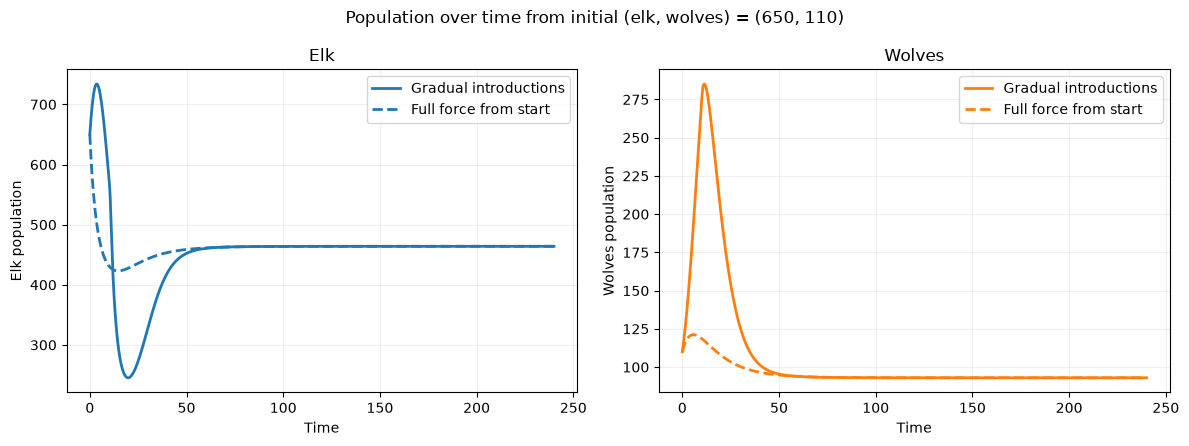

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, index, species, color in zip(axes, (0, 1), ('Elk', 'Wolves'), ('tab:blue', 'tab:orange')):
    ax.plot(introduced.t, introduced.y[index], color=color, lw=2, label='Gradual introductions')
    ax.plot(full_force.t, full_force.y[index], color=color, lw=2, ls='--', label='Full force from start')
    ax.set(xlabel='Time', ylabel=f'{species} population', title=species)
    ax.grid(alpha=.2)
    ax.legend()
fig.suptitle(f'Population over time from initial (elk, wolves) = {INITIAL}')
fig.tight_layout()
plt.show()


## Wolf versus elk

The gradual curve follows changing pressures during the ramp. The dashed curve uses maximum pressures throughout.

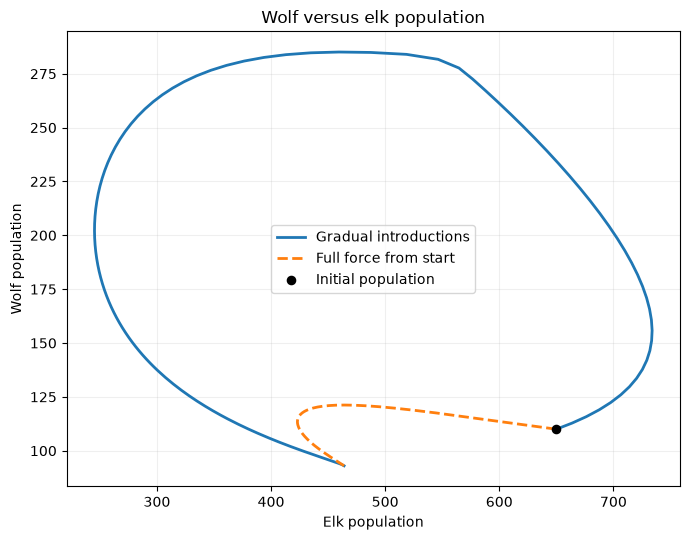

In [5]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(introduced.y[0], introduced.y[1], lw=2, label='Gradual introductions')
ax.plot(full_force.y[0], full_force.y[1], lw=2, ls='--', label='Full force from start')
ax.scatter(*INITIAL, color='black', s=35, zorder=3, label='Initial population')
ax.set(xlabel='Elk population', ylabel='Wolf population', title='Wolf versus elk population')
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()
plt.show()


## Farmer and hunter pressure

This confirms that the solid case ramps up while the full-force case begins at both configured maxima.

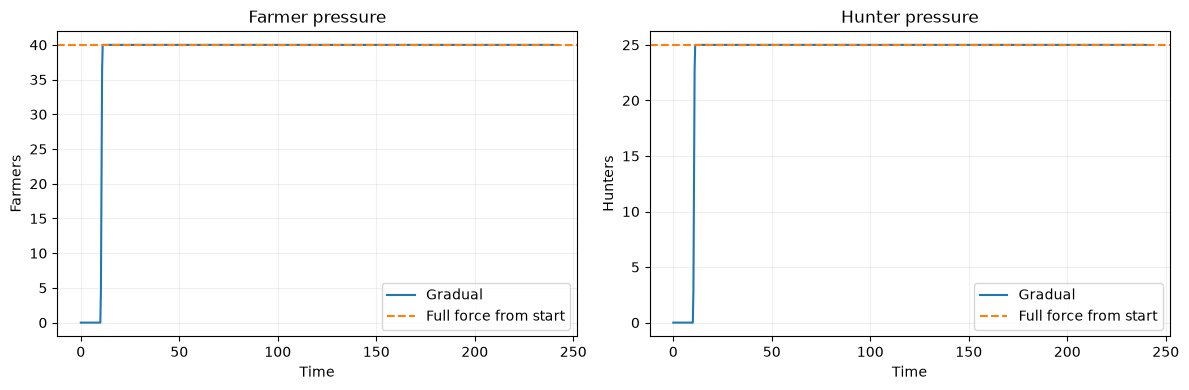

In [6]:
farmer_ramp = []
hunter_ramp = []
for t in times:
    farmer, hunter = pressures(t, 'both', INTRODUCTION_SHAPE,
                              MAX_FARMERS, MAX_HUNTERS,
                              INTRODUCTION_START, INTRODUCTION_DURATION)
    farmer_ramp.append(farmer)
    hunter_ramp.append(hunter)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
axes[0].plot(times, farmer_ramp, label='Gradual')
axes[0].axhline(MAX_FARMERS, color='tab:orange', ls='--', label='Full force from start')
axes[0].set(title='Farmer pressure', xlabel='Time', ylabel='Farmers')
axes[1].plot(times, hunter_ramp, label='Gradual')
axes[1].axhline(MAX_HUNTERS, color='tab:orange', ls='--', label='Full force from start')
axes[1].set(title='Hunter pressure', xlabel='Time', ylabel='Hunters')
for ax in axes: ax.grid(alpha=.2); ax.legend()
fig.tight_layout()
plt.show()
